In [2]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

import joblib


In [12]:
data = pd.read_excel("Churn Prediction.xlsx", sheet_name="vw_ChurnData")

data.head()

,Customer_ID,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,11098-MAD,Female,30,Yes,Madhya Pradesh,0,31,Deal 1,True,0,...,Bank Withdrawal,95.099998,6683.399902,0.00,0,631.719971,7315.120117,Stayed,Others,Others
1,11114-PUN,Male,51,No,Punjab,5,9,Deal 5,True,0,...,Bank Withdrawal,49.150002,169.050003,0.00,10,122.370003,301.420013,Churned,Competitor,Competitor had better devices
2,11167-WES,Female,43,Yes,West Bengal,3,28,Deal 1,True,1,...,Bank Withdrawal,116.050003,8297.500000,42.57,110,1872.979980,10237.910156,Stayed,Others,Others
3,11179-MAH,Male,35,No,Maharashtra,10,12,NaN,True,0,...,Credit Card,84.400002,5969.299805,0.00,0,219.389999,6188.689941,Stayed,Others,Others
4,11180-TAM,Male,75,Yes,Tamil Nadu,12,27,Deal 2,True,0,...,Credit Card,72.599998,4084.350098,0.00,140,332.079987,4556.430176,Stayed,Others,Others


In [13]:
data = data.drop(
    ['Customer_ID', 'Churn_Category', 'Churn_Reason'],
    axis=1
)



In [14]:
columns_to_encode = [
    'Gender', 'Married', 'State', 'Value_Deal',
    'Phone_Service', 'Multiple_Lines', 'Internet_Service',
    'Internet_Type', 'Online_Security', 'Online_Backup',
    'Device_Protection_Plan', 'Premium_Support',
    'Streaming_TV', 'Streaming_Movies', 'Streaming_Music',
    'Unlimited_Data', 'Contract', 'Paperless_Billing',
    'Payment_Method'
]


In [15]:
label_encoders = {}

for column in columns_to_encode:
    label_encoders[column] = LabelEncoder()
    data[column] = label_encoders[column].fit_transform(
        data[column].fillna('Unknown').astype(str)
    )


In [16]:
data['Customer_Status'] = data['Customer_Status'].map({
    'Stayed': 0,
    'Churned': 1
})


In [17]:
print("Missing target values:", data['Customer_Status'].isna().sum())


Missing target values: 0


In [18]:
data = data.dropna(subset=['Customer_Status'])


In [19]:
X = data.drop('Customer_Status', axis=1)
y = data['Customer_Status'].astype(int)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [21]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (4805, 28)
X_test: (1202, 28)
y_train: (4805,)
y_test: (1202,)


In [22]:

# 1. Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# 2. Train the model
rf_model.fit(X_train, y_train)

# 3. Make predictions on test data
y_pred = rf_model.predict(X_test)



In [23]:
# 4. Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 5. Feature Importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]



Confusion Matrix:
[[810  45]
 [144 203]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.95      0.90       855
           1       0.82      0.59      0.68       347

    accuracy                           0.84      1202
   macro avg       0.83      0.77      0.79      1202
weighted avg       0.84      0.84      0.83      1202



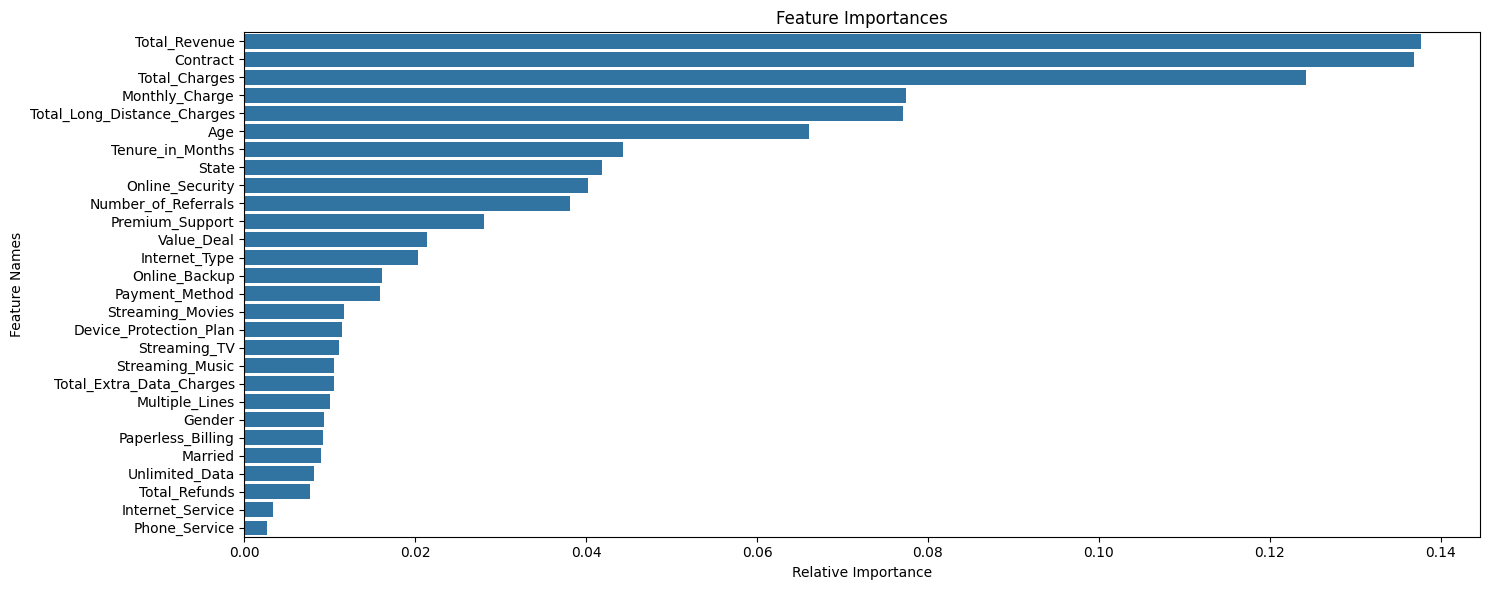

In [24]:
# 6. Plot Feature Importances
plt.figure(figsize=(15, 6))

sns.barplot(
    x=importances[indices],
    y=X.columns[indices]
)

plt.title("Feature Importances")
plt.xlabel("Relative Importance")
plt.ylabel("Feature Names")
plt.tight_layout()
plt.show()


In [26]:
# 1. Read new data
file_path = "Prediction_Data.xlsx"
sheet_name = "vw_JoinData"

new_data = pd.read_excel(
   "Churn Prediction.xlsx", sheet_name="vw_ChurnData"
)

print(new_data.head())

# 2. Preserve original data
original_data = new_data.copy()

# 3. Keep customer IDs
customer_ids = new_data["Customer_ID"].copy()

# 4. Remove columns not used for prediction
drop_columns = [
    "Customer_ID",
    "Customer_Status",
    "Churn_Category",
    "Churn_Reason"
]

new_data = new_data.drop(
    columns=drop_columns,
    errors="ignore"
)



  Customer_ID  Gender  Age Married           State  Number_of_Referrals  \
0   11098-MAD  Female   30     Yes  Madhya Pradesh                    0   
1   11114-PUN    Male   51      No          Punjab                    5   
2   11167-WES  Female   43     Yes     West Bengal                    3   
3   11179-MAH    Male   35      No     Maharashtra                   10   
4   11180-TAM    Male   75     Yes      Tamil Nadu                   12   

   Tenure_in_Months Value_Deal  Phone_Service Multiple_Lines  ...  \
0                31     Deal 1           True              0  ...   
1                 9     Deal 5           True              0  ...   
2                28     Deal 1           True              1  ...   
3                12        NaN           True              0  ...   
4                27     Deal 2           True              0  ...   

    Payment_Method Monthly_Charge Total_Charges Total_Refunds  \
0  Bank Withdrawal      95.099998   6683.399902          0.00   
1  B

In [27]:
# 5. Encode categorical columns using the training encoders
for column in columns_to_encode:
    if column in new_data.columns:
        encoder = label_encoders[column]

        values = new_data[column].fillna("Unknown").astype(str)

        # Map unseen categories to -1
        category_map = {
            category: index
            for index, category in enumerate(encoder.classes_)
        }

        new_data[column] = values.map(category_map).fillna(-1).astype(int)

# 6. Ensure columns match the training data
missing_columns = set(X.columns) - set(new_data.columns)
extra_columns = set(new_data.columns) - set(X.columns)

if missing_columns or extra_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}\n"
        f"Unexpected columns: {extra_columns}"
    )

new_data = new_data[X.columns]



In [28]:
# 7. Predict customer status
new_predictions = rf_model.predict(new_data)

# 8. Add predictions to original data
original_data["Customer_Status_Predicted"] = pd.Series(
    new_predictions,
    index=original_data.index
).map({
    0: "Stayed",
    1: "Churned"
})

# 9. Filter customers predicted to churn
churned_customers = original_data[
    original_data["Customer_Status_Predicted"] == "Churned"
].copy()

# 10. Save predictions
churned_customers.to_csv(
    "Predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Total customers:", len(original_data))
print("Predicted churned customers:", len(churned_customers))
print("Results saved to Predictions.csv")


Total customers: 6007
Predicted churned customers: 1633
Results saved to Predictions.csv
